In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

base = "/content/drive/MyDrive/NIR_Thesis"
clean = pd.read_csv(f"{base}/Data/my_data_clean.csv")
FT_DIR, MT_DIR = f"{base}/results/finetune", f"{base}/results/multitask"
out = f"{base}/results/figures"
os.makedirs(out, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
def make_split(df, seed):
    groups = df.groupby("scaffold").size().sample(frac=1, random_state=seed)
    big = groups[groups > len(df) * 0.005].index.tolist()
    small = [g for g in groups.index if g not in set(big)]
    split, count, n = {}, 0, len(df)
    for g in big + small:
        split[g] = "train" if count < 0.8 * n else ("val" if count < 0.9 * n else "test")
        count += groups[g]
    return df.scaffold.map(split)

SEEDS = [42, 0, 1, 2, 3]
parts = []
for s in SEEDS:
    t = clean[make_split(clean, s) == "test"].reset_index(drop=True)
    P = {"General": 1239.84 / pd.read_csv(f"{FT_DIR}/preds_base_seed{s}.csv").iloc[:, -1].values,
         "Fine-tuned alone": 1239.84 / pd.read_csv(f"{FT_DIR}/preds_ft_seed{s}.csv").iloc[:, -1].values,
         "Red-only": 1239.84 / pd.read_csv(f"{FT_DIR}/preds_red_only_seed{s}.csv").iloc[:, -1].values}
    mt = pd.read_csv(f"{MT_DIR}/preds_mt_seed{s}.csv")
    P["Multitask"] = 1239.84 / mt["emi_eV"].values
    P["Two-stage"] = np.where(P["General"] >= 600, P["Fine-tuned alone"], P["General"])
    P["Average (general + multitask)"] = (P["General"] + P["Multitask"]) / 2
    df = pd.DataFrame({"seed": s, "true": t.emi_nm.values, "abs_true": t.abs_nm.values,
                       "abs_pred": 1239.84 / mt["abs_eV"].values})
    for k, v in P.items():
        df[k] = v
    parts.append(df)
allp = pd.concat(parts, ignore_index=True)

# one colour per approach, checked for colour-blind safety; general model stays blue as in earlier figures
C = {"General": "#2a78d6", "Fine-tuned alone": "#e34948", "Red-only": "#eda100", "Two-stage": "#1baf7a",
     "Multitask": "#e87ba4", "Average (general + multitask)": "#008300"}
INK, MUTED, GRID, CONTEXT = "#1f2328", "#5f6368", "#e6e6e3", "#c9c9c4"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlelocation": "left", "axes.titlesize": 11,
                     "legend.frameon": False, "savefig.dpi": 300, "savefig.bbox": "tight"})
BINS = [("< 500", 0, 500), ("500–650", 500, 650), ("650–700", 650, 700), ("≥ 700", 700, 2000)]
print(len(allp), "test predictions across", allp.seed.nunique(), "splits")

8894 test predictions across 5 splits


In [6]:
def bin_bars(models, title, fname, ylim=None, legend_loc="upper left"):
    rows = []
    for s, g in allp.groupby("seed"):
        for name in models:
            for lab, lo, hi in BINS:
                m = (g.true >= lo) & (g.true < hi)
                rows.append({"model": name, "bin": lab, "MAE": (g[name][m] - g.true[m]).abs().mean()})
    summ = pd.DataFrame(rows).groupby(["model", "bin"], sort=False).MAE.agg(["mean", "std"]).reset_index()
    fig, ax = plt.subplots(figsize=(8.5, 4.2))
    x = np.arange(len(BINS)); w = 0.8 / len(models)
    for i, name in enumerate(models):
        s = summ[summ.model == name].set_index("bin").loc[[b[0] for b in BINS]]
        xs = x + (i - (len(models) - 1) / 2) * w
        ax.bar(xs, s["mean"], w, yerr=s["std"], color=C[name], edgecolor="white", lw=1.5,
               error_kw={"ecolor": INK, "elinewidth": 1, "capsize": 2}, label=name)
        if ylim:   # label bars that run off the top of the chart
            for xi, v in zip(xs, s["mean"]):
                if v > ylim:
                    ax.text(xi, ylim * 0.97, f"{v:.0f}", ha="center", va="top", fontsize=8, color="white", fontweight="bold")
    ax.set_xticks(x, [f"{b[0]} nm" for b in BINS])
    if ylim:
        ax.set_ylim(0, ylim)
    ax.set_ylabel("Test MAE (nm), mean ± SD over 5 splits")
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_title(title); ax.legend(loc=legend_loc, fontsize=9, ncol=2)
    fig.tight_layout(); fig.savefig(f"{out}/{fname}"); plt.show()

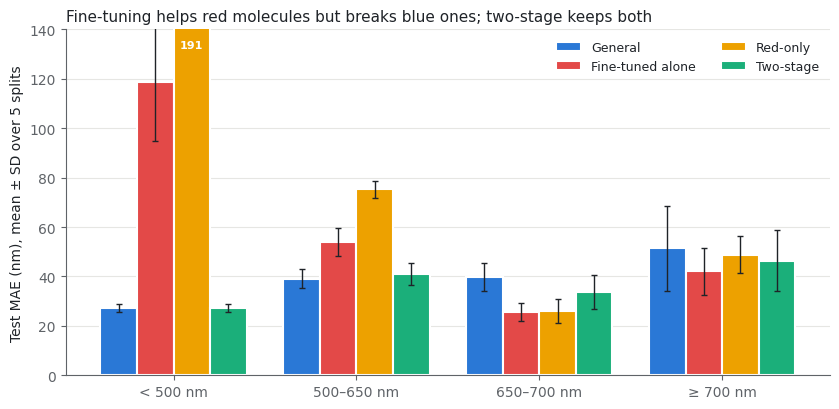

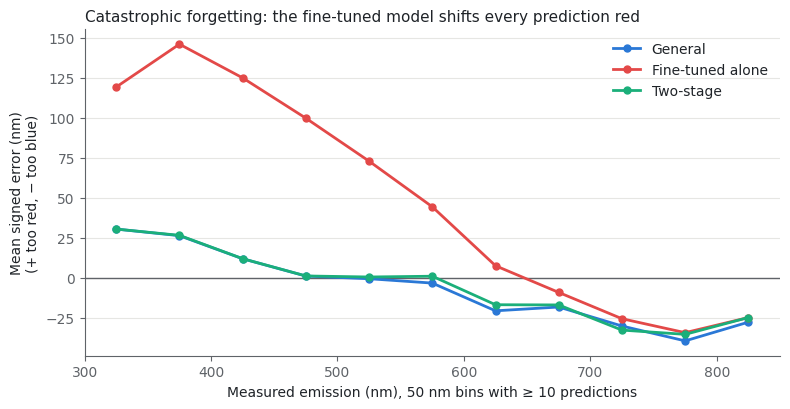

In [7]:
bin_bars(["General", "Fine-tuned alone", "Red-only", "Two-stage"],
         "Fine-tuning helps red molecules but breaks blue ones; two-stage keeps both",
         "fig_ft_mae_by_bin.png", ylim=140, legend_loc="upper right")

edges = np.arange(300, 901, 50)
wbin = pd.cut(allp.true, edges)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.axhline(0, color=MUTED, lw=1)
for name in ["General", "Fine-tuned alone", "Two-stage"]:
    g = (allp[name] - allp.true).groupby(wbin, observed=True).agg(["mean", "count"])
    g = g[g["count"] >= 10]
    ax.plot([iv.mid for iv in g.index], g["mean"], color=C[name], lw=2, marker="o", ms=5, label=name)
ax.set_xlabel("Measured emission (nm), 50 nm bins with ≥ 10 predictions")
ax.set_ylabel("Mean signed error (nm)\n(+ too red, − too blue)")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("Catastrophic forgetting: the fine-tuned model shifts every prediction red")
ax.legend(loc="upper right")
fig.tight_layout(); fig.savefig(f"{out}/fig_ft_bias_curves.png"); plt.show()

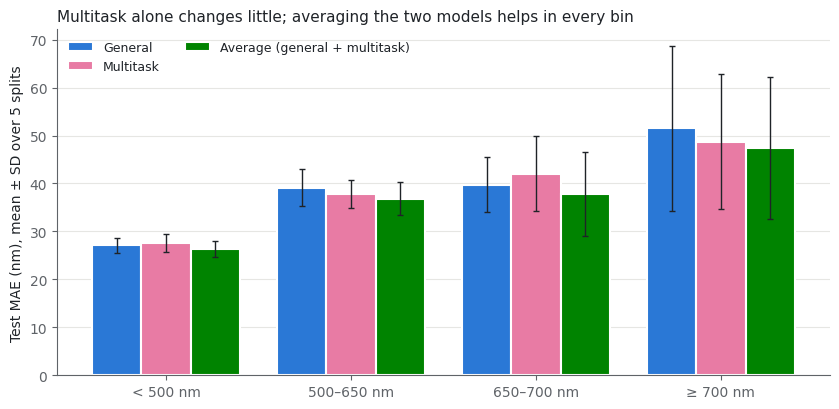

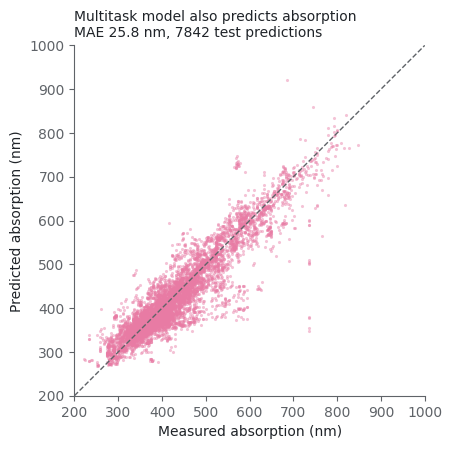

In [8]:
bin_bars(["General", "Multitask", "Average (general + multitask)"],
         "Multitask alone changes little; averaging the two models helps in every bin",
         "fig_mt_mae_by_bin.png")

a = allp.dropna(subset=["abs_true"])
fig, ax = plt.subplots(figsize=(4.6, 4.6))
ax.scatter(a.abs_true, a.abs_pred, s=5, color=C["Multitask"], alpha=0.45, lw=0, rasterized=True)
ax.plot([200, 1000], [200, 1000], color=MUTED, lw=1, ls="--")
ax.set_xlim(200, 1000); ax.set_ylim(200, 1000); ax.set_aspect("equal")
ax.set_xlabel("Measured absorption (nm)"); ax.set_ylabel("Predicted absorption (nm)")
ax.set_title(f"Multitask model also predicts absorption\n"
             f"MAE {(a.abs_pred - a.abs_true).abs().mean():.1f} nm, {len(a)} test predictions", fontsize=10)
fig.tight_layout(); fig.savefig(f"{out}/fig_mt_absorption_parity.png"); plt.show()

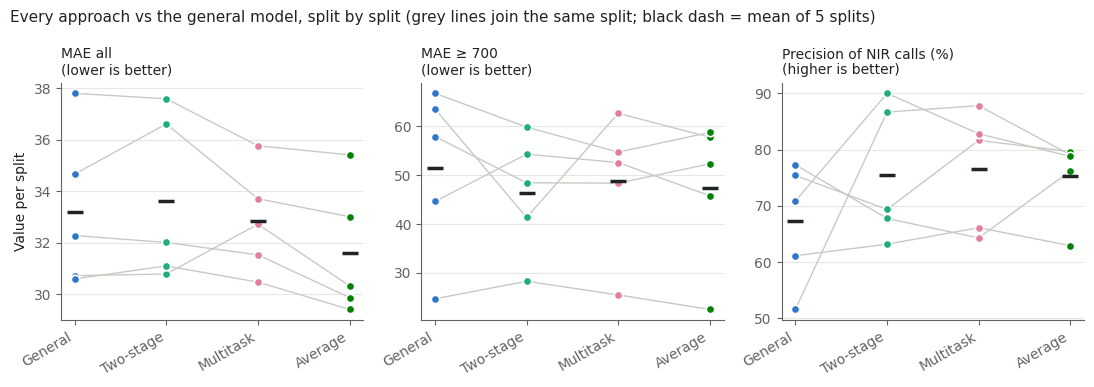

In [10]:
APPROACHES = ["General", "Two-stage", "Multitask", "Average (general + multitask)"]
LABELS = ["General", "Two-stage", "Multitask", "Average"]

def split_metrics(g, name):
    p, t = g[name].values, g.true.values
    hit = p >= 700
    return {"MAE all": np.abs(p - t).mean(), "MAE ≥ 700": np.abs(p - t)[t >= 700].mean(),
            "Precision of NIR calls (%)": 100 * (t[hit] >= 700).mean()}

sm = pd.DataFrame([{"seed": s, "model": n, **split_metrics(g, n)}
                   for s, g in allp.groupby("seed") for n in APPROACHES])
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, metric in zip(axes, ["MAE all", "MAE ≥ 700", "Precision of NIR calls (%)"]):
    piv = sm.pivot(index="seed", columns="model", values=metric)[APPROACHES]
    for _, r in piv.iterrows():
        ax.plot(range(len(APPROACHES)), r.values, color=CONTEXT, lw=1, zorder=1)
    for i, name in enumerate(APPROACHES):
        ax.scatter([i] * len(piv), piv[name], s=36, color=C[name], edgecolor="white", lw=1.2, zorder=2)
        ax.scatter(i, piv[name].mean(), s=140, marker="_", color=INK, lw=2.5, zorder=3)
    ax.set_xticks(range(len(APPROACHES)), LABELS, rotation=30, ha="right")
    better = "higher is better" if "Precision" in metric else "lower is better"
    ax.set_title(f"{metric}\n({better})", fontsize=10)
    ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel("Value per split")
fig.suptitle("Every approach vs the general model, split by split "
             "(grey lines join the same split; black dash = mean of 5 splits)",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(f"{out}/fig_paired_all_approaches.png"); plt.show()